In [8]:
from pathlib import Path
import pandas as pd

SCENARIOS = ["C1", "C2", "C3", "C4"]
resource_results = {}

columns = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st", "date", "time"
]

for scenario in SCENARIOS:
    data = []

    for file in sorted(Path(scenario).glob("*_vmstat.txt")):
        parts = file.stem.split("_")
        app = parts[1]
        users = int(parts[2].replace("users", ""))

        rows = []
        for line in file.read_text().splitlines():
            values = line.split()
            if len(values) != 19:
                continue
            try:
                rows.append(values)
            except ValueError:
                continue

        if len(rows) < 2:
            continue

        df = pd.DataFrame(rows, columns=columns)
        df = df.iloc[1:].copy()  # discard first vmstat sample

        for col in columns[:17]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        data.append({
            "application": app,
            "users": users,
            "cpu_util_pct": 100 - df["id"].mean(),
            "free_memory_mb": df["free"].mean() / 1024,
        })

    resource_results[scenario] = pd.DataFrame(data)

for scenario, df in resource_results.items():
    print(f"{scenario}: {len(df)} tests")
    display(df)

C1: 8 tests


,application,users,cpu_util_pct,free_memory_mb
0,cpu,100,8.411765,66.686121
1,cpu,200,12.235294,65.651195
2,cpu,300,15.647059,62.519531
3,cpu,400,23.235294,60.029182
4,memory,100,5.647059,64.582950
5,memory,200,8.647059,64.693704
6,memory,300,11.294118,62.534697
7,memory,400,11.470588,69.742188


C2: 8 tests


,application,users,cpu_util_pct,free_memory_mb
0,cpu,100,21.294118,71.227252
1,cpu,200,24.117647,68.814798
2,cpu,300,20.058824,62.994945
3,cpu,400,25.235294,64.539062
4,memory,100,10.411765,65.979550
5,memory,200,11.705882,90.409697
6,memory,300,15.117647,89.649586
7,memory,400,15.411765,88.746324


C3: 8 tests


,application,users,cpu_util_pct,free_memory_mb
0,cpu,100,13.176471,62.820312
1,cpu,200,15.117647,65.798713
2,cpu,300,16.000000,64.871783
3,cpu,400,17.764706,62.213925
4,memory,100,7.705882,76.570772
5,memory,200,6.823529,68.081572
6,memory,300,8.000000,62.359375
7,memory,400,9.294118,60.047335


C4: 8 tests


,application,users,cpu_util_pct,free_memory_mb
0,cpu,100,13.588235,73.631893
1,cpu,200,16.588235,71.207491
2,cpu,300,15.058824,72.409007
3,cpu,400,17.235294,72.535156
4,memory,100,10.176471,135.965763
5,memory,200,8.294118,166.753906
6,memory,300,9.529412,157.562960
7,memory,400,11.764706,196.028722


C1:


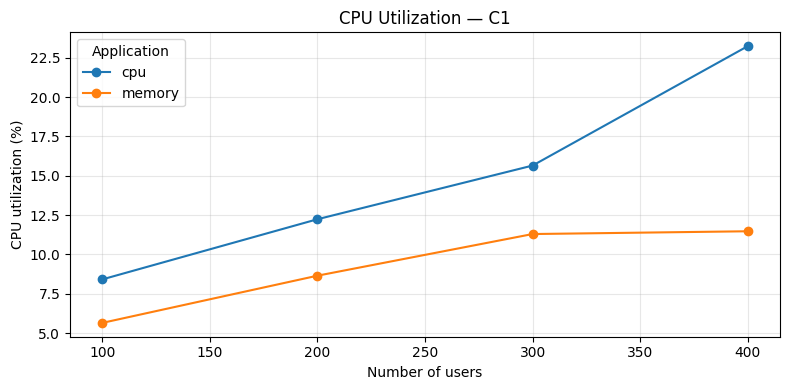

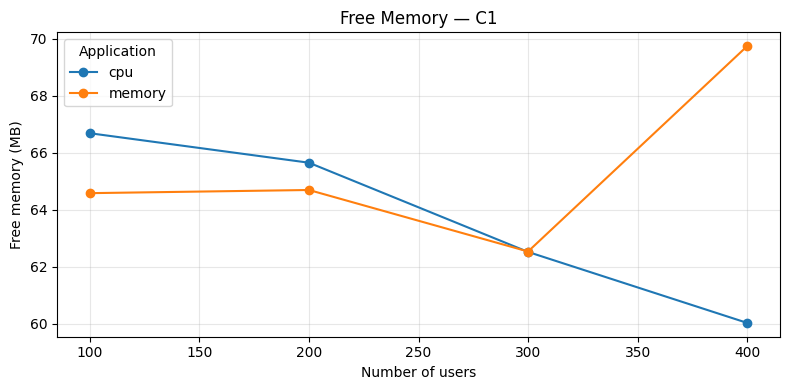

C2:


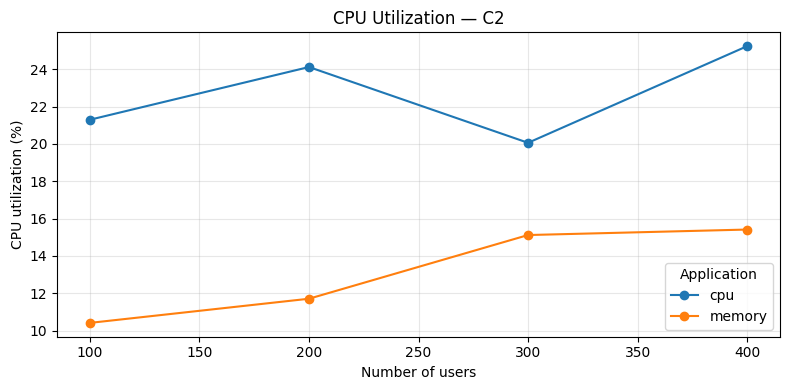

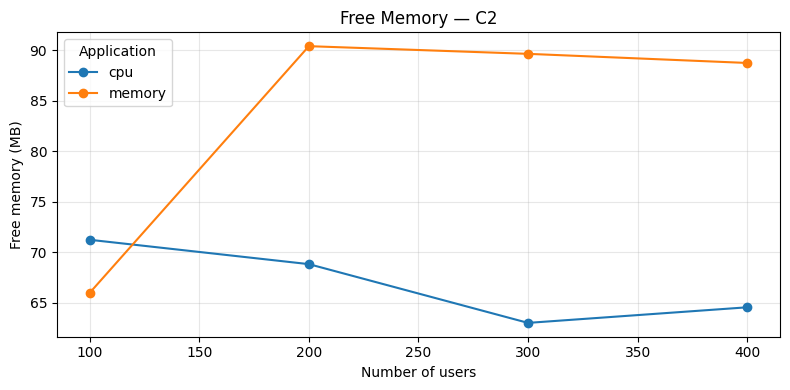

C3:


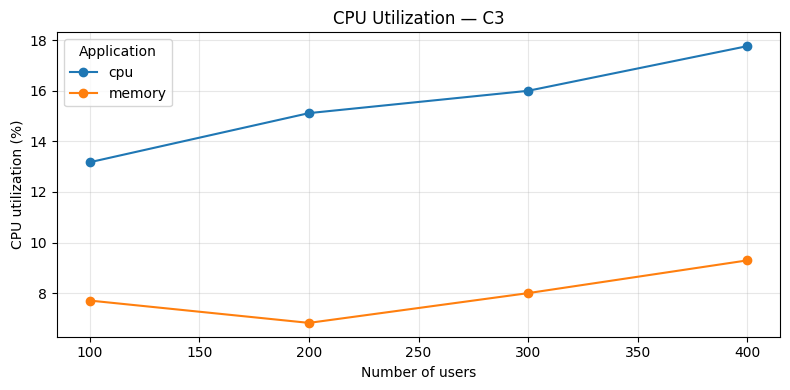

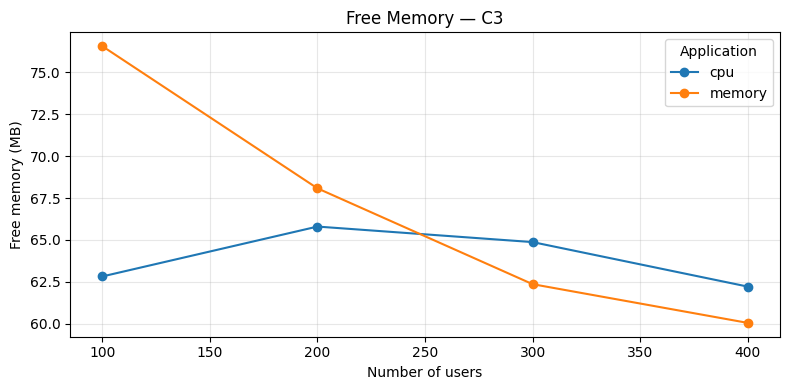

C4:


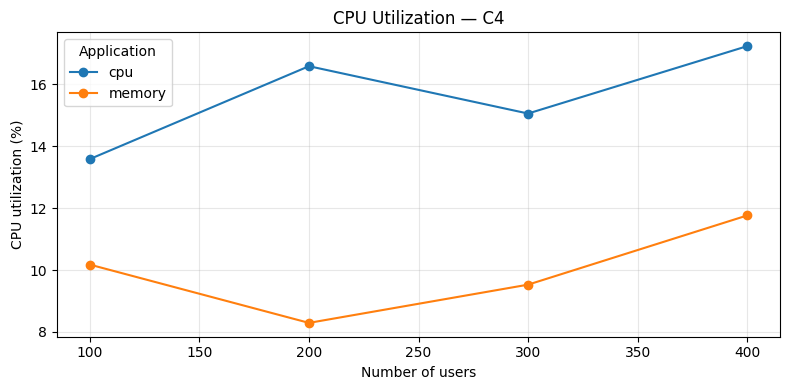

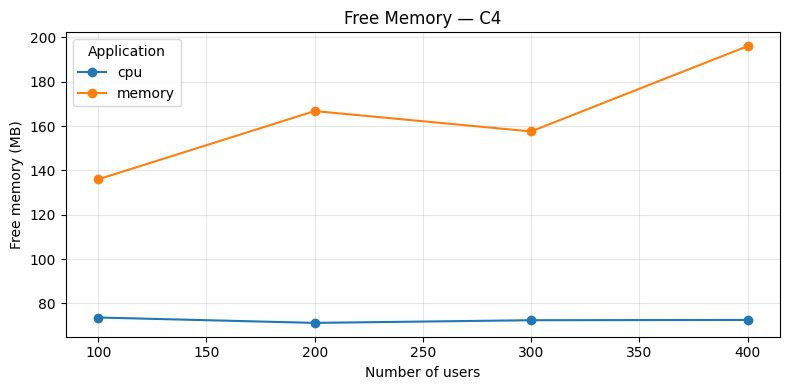

In [9]:
import matplotlib.pyplot as plt

for scenario, df in resource_results.items():
    print(f"{scenario}:")

    if df.empty:
        print("No data available.")
        continue

    # CPU usage
    plt.figure(figsize=(8, 4))
    for app, group in df.groupby("application"):
        plt.plot(group["users"], group["cpu_util_pct"],
                 marker="o", label=app)
    plt.xlabel("Number of users")
    plt.ylabel("CPU utilization (%)")
    plt.title(f"CPU Utilization — {scenario}")
    plt.grid(True, alpha=0.3)
    plt.legend(title="Application")
    plt.tight_layout()
    plt.show()

    # Memory usage (free RAM)
    plt.figure(figsize=(8, 4))
    for app, group in df.groupby("application"):
        plt.plot(group["users"], group["free_memory_mb"],
                 marker="o", label=app)
    plt.xlabel("Number of users")
    plt.ylabel("Free memory (MB)")
    plt.title(f"Free Memory — {scenario}")
    plt.grid(True, alpha=0.3)
    plt.legend(title="Application")
    plt.tight_layout()
    plt.show()

C1:


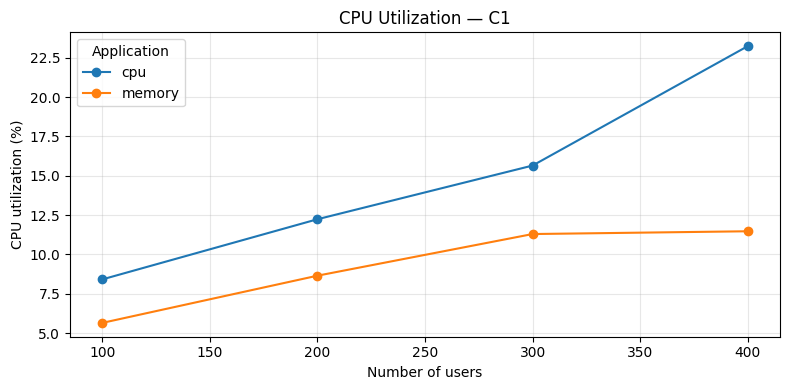

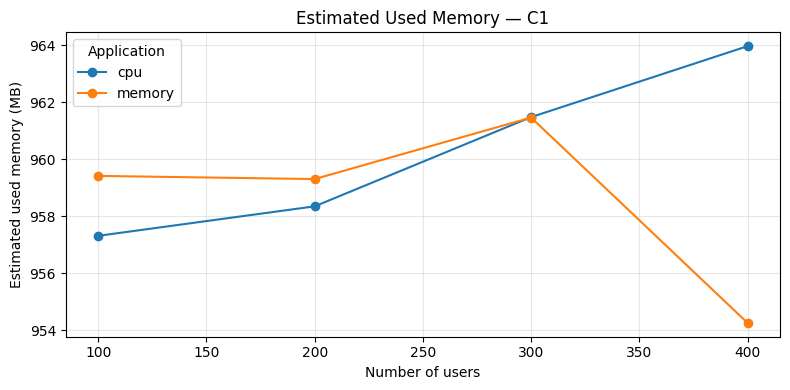

C2:


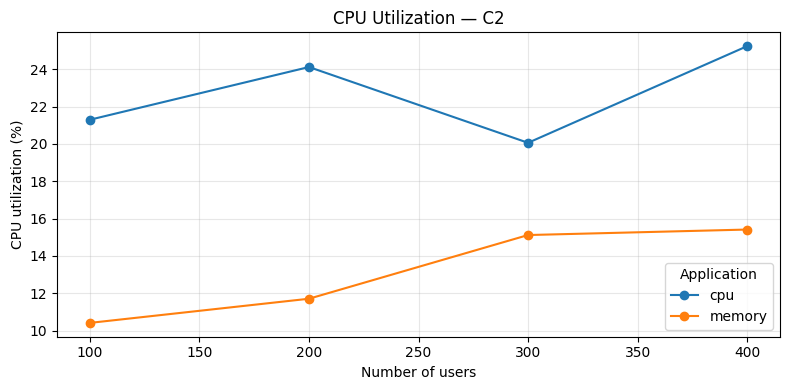

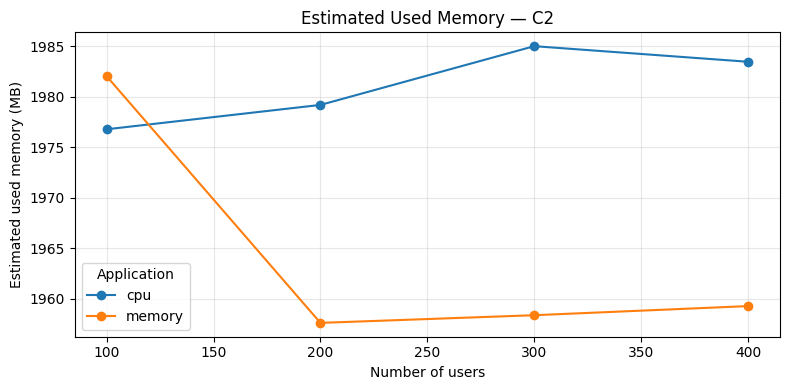

C3:


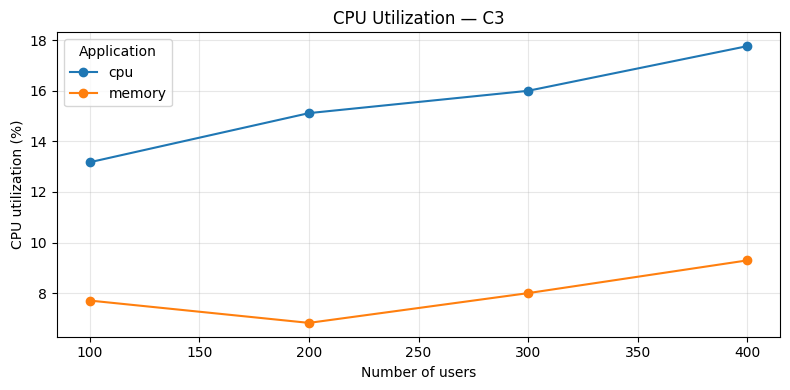

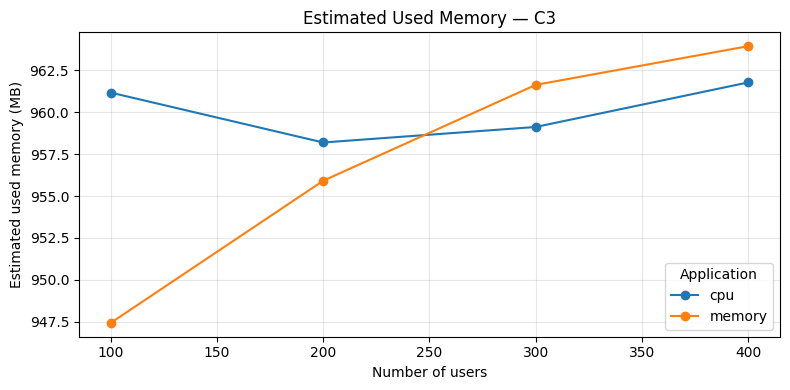

C4:


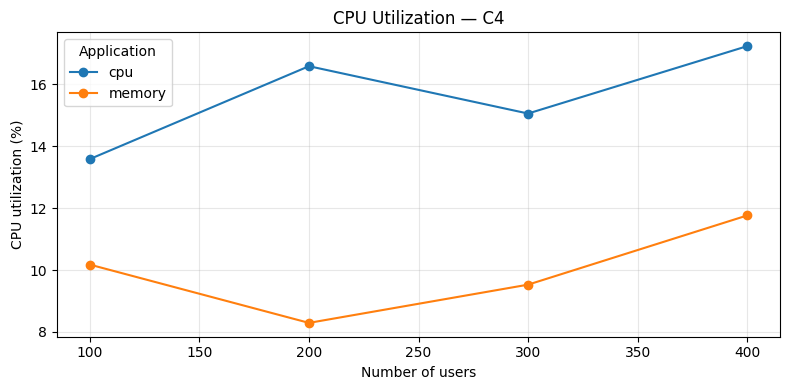

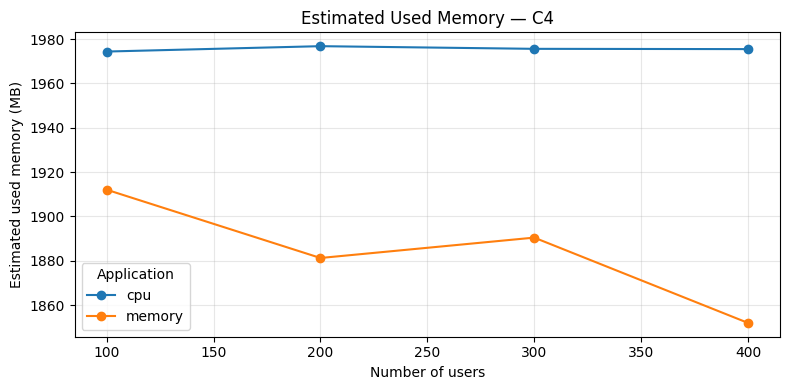

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SCENARIOS = ["C1", "C2", "C3", "C4"]
RAM_MB = {"C1": 1024, "C2": 2048, "C3": 1024, "C4": 2048}

resource_results = {}

columns = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st", "date", "time"
]

for scenario in SCENARIOS:
    data = []

    for file in sorted(Path(scenario).glob("*_vmstat.txt")):
        parts = file.stem.split("_")
        app = parts[1]
        users = int(parts[2].replace("users", ""))

        rows = []
        for line in file.read_text().splitlines():
            values = line.split()
            if len(values) != 19:
                continue
            try:
                [float(v) for v in values[:17]]
                rows.append(values)
            except ValueError:
                continue

        if len(rows) < 2:
            continue

        df = pd.DataFrame(rows, columns=columns).iloc[1:].copy()

        for col in columns[:17]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        data.append({
            "application": app,
            "users": users,
            "cpu_util_pct": 100 - df["id"].mean(),
            "used_memory_mb": RAM_MB[scenario] - df["free"].mean() / 1024,
        })

    resource_results[scenario] = pd.DataFrame(data)

for scenario, df in resource_results.items():
    print(f"{scenario}:")

    if df.empty:
        print("No data available.")
        continue

    for metric, ylabel, title in [
        ("cpu_util_pct", "CPU utilization (%)", "CPU Utilization"),
        ("used_memory_mb", "Estimated used memory (MB)", "Estimated Used Memory"),
    ]:
        plt.figure(figsize=(8, 4))

        for app, group in df.groupby("application"):
            if app == "io":
                continue
            plt.plot(group["users"], group[metric],
                     marker="o", label=app)

        plt.xlabel("Number of users")
        plt.ylabel(ylabel)
        plt.title(f"{title} — {scenario}")
        plt.grid(True, alpha=0.3)
        plt.legend(title="Application")
        plt.tight_layout()
        plt.show()